# Phase 0: Data Preparation — Task B (20-class Species Classification)

**Task B**: Classify 20 species (not 4 families).

> **Note**: Stratified split by species, seed=42, same 70/15/15 ratios as Task A.

## 1. Configuration

In [11]:
# Configuration
RAW_DATA_PATH = "../../data/raw"
OUTPUT_DIR = "../../data/task-B"
LABEL_MAPPING_PATH = "../../data/task-B/species_labels.json"

# Split ratios (same as Task A)
TRAIN_RATIO = 0.7
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# Random seed for reproducibility
RANDOM_SEED = 42

import os
for split in ['train', 'val', 'test']:
    os.makedirs(f"{OUTPUT_DIR}/{split}", exist_ok=True)

In [12]:
import os
import glob
import json
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shutil
from PIL import Image
from pathlib import Path
from sklearn.model_selection import train_test_split

plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

## 2. Species-to-Family Mapping (for reference)

In [13]:
# Species to Family mapping (same as Task A)
SPECIES_TO_FAMILY = {
    # Cupressaceae (10 species)
    "3244.Calocedrus sp": "Cupressaceae",
    "3252.Callitris columellaris": "Cupressaceae",
    "3273.Fokienia hodginsii": "Cupressaceae",
    "3274.Cunninghamia lanceolata": "Cupressaceae",
    "3314.Cupressus funebris (Cupressus pendula)": "Cupressaceae",
    "3342.Calocedrus rupestris": "Cupressaceae",
    "3341.Xanthocyparis vietnamensis": "Cupressaceae",
    "3350.Cryptomeria japonica": "Cupressaceae",
    "3364.Chamaecyparis obtusa": "Cupressaceae",
    "3387.Thujopsis dolabrata": "Cupressaceae",
    
    # Pinaceae (9 species)
    "3325.Pinus sp": "Pinaceae",
    "3378.Picea glauca": "Pinaceae",
    "3379.Pinus radiata": "Pinaceae",
    "3383.Pseudotsuga brevifolia": "Pinaceae",
    "3384.Pinus krempfii": "Pinaceae",
    "3385.Pinus cernua": "Pinaceae",
    "3393.Pinus dalatensis": "Pinaceae",
    "3351.Araucaria araucana": "Pinaceae",
    
    # Podocarpaceae (1 species)
    "3386.Podocarpus pilgeri": "Podocarpaceae",
    
    # Taxaceae (1 species)
    "3391.Taxus wallichiana": "Taxaceae",
}

# Family labels (same as Task A)
FAMILY_LABELS = {
    "Cupressaceae": 0,
    "Pinaceae": 1,
    "Podocarpaceae": 2,
    "Taxaceae": 3
}

print(f"Total families: {len(FAMILY_LABELS)}")
print(f"Total species: {len(SPECIES_TO_FAMILY)}")

Total families: 4
Total species: 20


## 3. Create Species Labels (Task B: 20-class)

In [14]:
# Create species labels dict (Task B: 20 classes)
species_list = sorted(SPECIES_TO_FAMILY.keys())
SPECIES_LABELS = {species: idx for idx, species in enumerate(species_list)}

# Create label mapping JSON
species_labels_json = {
    "families": FAMILY_LABELS,
    "species": SPECIES_LABELS,
    "family_of_species": {
        species: FAMILY_LABELS[family] 
        for species, family in SPECIES_TO_FAMILY.items()
    }
}

# Save to file
os.makedirs(os.path.dirname(LABEL_MAPPING_PATH), exist_ok=True)
with open(LABEL_MAPPING_PATH, 'w') as f:
    json.dump(species_labels_json, f, indent=2)

print(f"Total species (classes): {len(SPECIES_LABELS)}")
print("\nSpecies labels:")
for idx, (species, label) in enumerate(sorted(SPECIES_LABELS.items(), key=lambda x: x[1])):
    family = SPECIES_TO_FAMILY[species]
    print(f"  {label}: {species} ({family})")

Total species (classes): 20

Species labels:
  0: 3244.Calocedrus sp (Cupressaceae)
  1: 3252.Callitris columellaris (Cupressaceae)
  2: 3273.Fokienia hodginsii (Cupressaceae)
  3: 3274.Cunninghamia lanceolata (Cupressaceae)
  4: 3314.Cupressus funebris (Cupressus pendula) (Cupressaceae)
  5: 3325.Pinus sp (Pinaceae)
  6: 3341.Xanthocyparis vietnamensis (Cupressaceae)
  7: 3342.Calocedrus rupestris (Cupressaceae)
  8: 3350.Cryptomeria japonica (Cupressaceae)
  9: 3351.Araucaria araucana (Pinaceae)
  10: 3364.Chamaecyparis obtusa (Cupressaceae)
  11: 3378.Picea glauca (Pinaceae)
  12: 3379.Pinus radiata (Pinaceae)
  13: 3383.Pseudotsuga brevifolia (Pinaceae)
  14: 3384.Pinus krempfii (Pinaceae)
  15: 3385.Pinus cernua (Pinaceae)
  16: 3386.Podocarpus pilgeri (Podocarpaceae)
  17: 3387.Thujopsis dolabrata (Cupressaceae)
  18: 3391.Taxus wallichiana (Taxaceae)
  19: 3393.Pinus dalatensis (Pinaceae)


## 4. Collect All Images

In [15]:
# Collect all images with their species and family labels
# Extract clean species name: "3244.Calocedrus sp" -> "Calocedrus sp"
image_extensions = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}

all_images = []
for folder in os.listdir(RAW_DATA_PATH):
    folder_path = os.path.join(RAW_DATA_PATH, folder)
    
    if not os.path.isdir(folder_path) or folder == '__MACOSX':
        continue
    
    species = folder
    species_clean = folder.split('.', 1)[-1].strip()
    
    if species not in SPECIES_LABELS:
        print(f"Warning: Unknown species '{species}' in raw data")
        continue
    
    family = SPECIES_TO_FAMILY.get(species, 'Unknown')
    
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if Path(file).suffix.lower() in image_extensions:
                all_images.append({
                    'path': os.path.join(root, file),
                    'species': species,
                    'species_clean': species_clean,
                    'species_idx': SPECIES_LABELS[species],
                    'family': family,
                    'family_idx': FAMILY_LABELS[family]
                })

print(f"Total images collected: {len(all_images)}")

# Create DataFrame
df = pd.DataFrame(all_images)
print("\nSpecies distribution:")
print(df['species'].value_counts().sort_index())

print("\nFamily distribution:")
print(df['family'].value_counts())

Total images collected: 6423

Species distribution:
species
3244.Calocedrus sp                             238
3252.Callitris columellaris                    416
3273.Fokienia hodginsii                        412
3274.Cunninghamia lanceolata                   450
3314.Cupressus funebris (Cupressus pendula)    318
3325.Pinus sp                                  216
3341.Xanthocyparis vietnamensis                318
3342.Calocedrus rupestris                      302
3350.Cryptomeria japonica                      335
3351.Araucaria araucana                        300
3364.Chamaecyparis obtusa                      317
3378.Picea glauca                              304
3379.Pinus radiata                             332
3383.Pseudotsuga brevifolia                    289
3384.Pinus krempfii                            323
3385.Pinus cernua                              287
3386.Podocarpus pilgeri                        310
3387.Thujopsis dolabrata                       327
3391.Taxus wallichiana

## 5. Stratified Split by Species

In [16]:
# Stratified split: first split train vs (val+test), then val vs test
# This ensures each species is represented in all splits

# First split: 70% train, 30% temp
train_df, temp_df = train_test_split(
    df, 
    test_size=VAL_RATIO + TEST_RATIO,  # 0.30
    stratify=df['species'],
    random_state=RANDOM_SEED
)

# Second split: 50% of temp = 15%, remaining = 15%
val_df, test_df = train_test_split(
    temp_df, 
    test_size=TEST_RATIO / (VAL_RATIO + TEST_RATIO),  # 0.50 of 0.30 = 0.15
    stratify=temp_df['species'],
    random_state=RANDOM_SEED
)

print(f"Train: {len(train_df)} ({len(train_df)/len(df)*100:.1f}%)")
print(f"Val:   {len(val_df)} ({len(val_df)/len(df)*100:.1f}%)")
print(f"Test:  {len(test_df)} ({len(test_df)/len(df)*100:.1f}%)")

# Verify stratified split
print("\n--- Verification: Species distribution per split ---")
for species in sorted(SPECIES_LABELS.keys()):
    train_count = len(train_df[train_df['species'] == species])
    val_count = len(val_df[val_df['species'] == species])
    test_count = len(test_df[test_df['species'] == species])
    total = train_count + val_count + test_count
    print(f"  {species}: train={train_count}, val={val_count}, test={test_count} (total={total})")

Train: 4496 (70.0%)
Val:   963 (15.0%)
Test:  964 (15.0%)

--- Verification: Species distribution per split ---
  3244.Calocedrus sp: train=167, val=36, test=35 (total=238)
  3252.Callitris columellaris: train=291, val=62, test=63 (total=416)
  3273.Fokienia hodginsii: train=288, val=62, test=62 (total=412)
  3274.Cunninghamia lanceolata: train=315, val=67, test=68 (total=450)
  3314.Cupressus funebris (Cupressus pendula): train=223, val=47, test=48 (total=318)
  3325.Pinus sp: train=151, val=33, test=32 (total=216)
  3341.Xanthocyparis vietnamensis: train=223, val=47, test=48 (total=318)
  3342.Calocedrus rupestris: train=211, val=46, test=45 (total=302)
  3350.Cryptomeria japonica: train=234, val=50, test=51 (total=335)
  3351.Araucaria araucana: train=210, val=45, test=45 (total=300)
  3364.Chamaecyparis obtusa: train=222, val=47, test=48 (total=317)
  3378.Picea glauca: train=213, val=46, test=45 (total=304)
  3379.Pinus radiata: train=232, val=50, test=50 (total=332)
  3383.Pseudo

## 6. Copy Images to Split Folders

In [17]:
# Copy images to split directories
# Structure: data/task-B/{split}/{family}/{species}/images.jpg

def copy_images(df, split_name):
    split_dir = f"{OUTPUT_DIR}/{split_name}"
    os.makedirs(split_dir, exist_ok=True)
    
    for _, row in df.iterrows():
        # Create nested structure: {family}/{species}
        # e.g., "Cupressaceae/Cunninghamia lanceolata"
        family_folder = row['family']
        species_folder = row['species_clean']
        target_dir = os.path.join(split_dir, family_folder, species_folder)
        os.makedirs(target_dir, exist_ok=True)
        
        # Copy image
        filename = os.path.basename(row['path'])
        target_path = os.path.join(target_dir, filename)
        shutil.copy2(row['path'], target_path)
    
    print(f"{split_name}: copied {len(df)} images to {split_dir}")

copy_images(train_df, 'train')
copy_images(val_df, 'val')
copy_images(test_df, 'test')

train: copied 4496 images to ../../data/task-B/train
val: copied 963 images to ../../data/task-B/val
test: copied 964 images to ../../data/task-B/test


## 7. Save Split Metadata

In [18]:
# Save split metadata
split_metadata = {
    'train': train_df.to_dict('records'),
    'val': val_df.to_dict('records'),
    'test': test_df.to_dict('records'),
    'summary': {
        'total_images': len(df),
        'total_species': len(SPECIES_LABELS),
        'total_families': len(FAMILY_LABELS),
        'split_ratios': {
            'train': len(train_df)/len(df),
            'val': len(val_df)/len(df),
            'test': len(test_df)/len(df)
        },
        'seed': RANDOM_SEED
    }
}

metadata_path = f"{OUTPUT_DIR}/split_metadata.json"
with open(metadata_path, 'w') as f:
    json.dump(split_metadata, f, indent=2)

print(f"Split metadata saved to {metadata_path}")

Split metadata saved to ../../data/task-B/split_metadata.json


## 8. Visualize Split Distribution

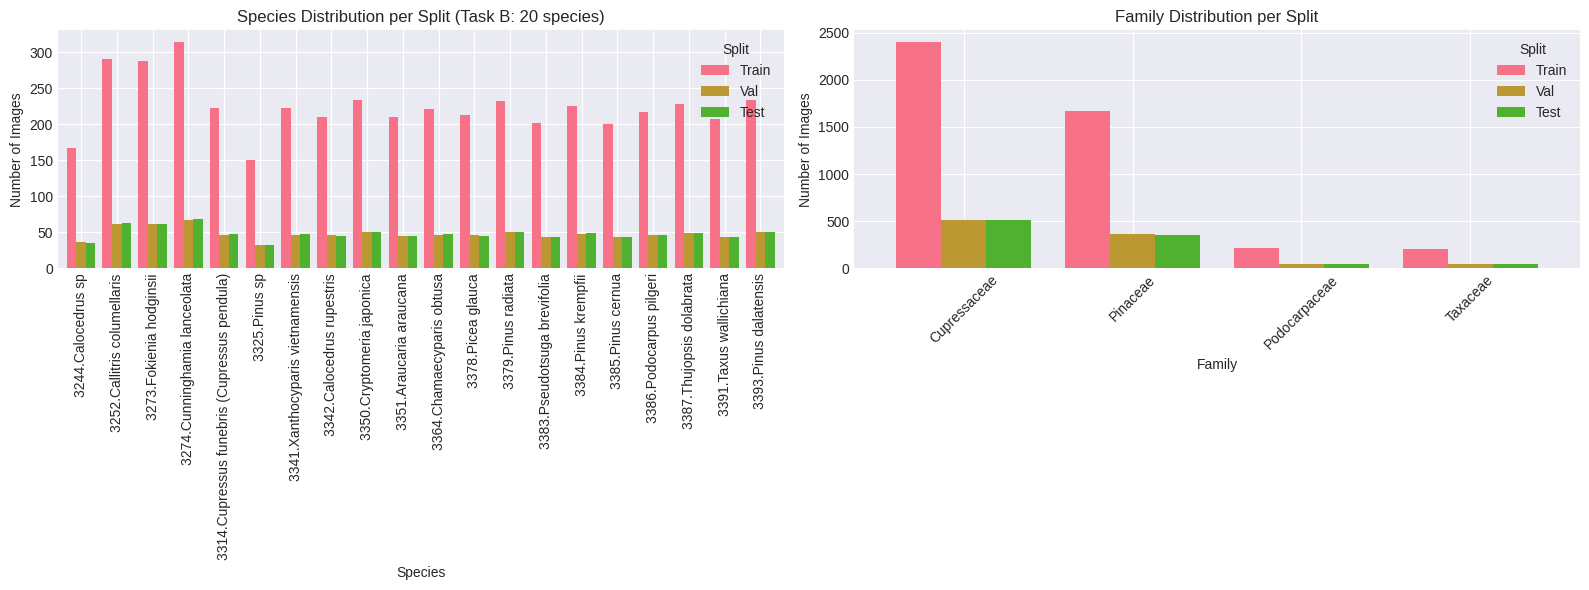

Plot saved to ../../data/task-B/split_distribution.png


In [19]:
# Plot species distribution per split
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Per species
train_counts = train_df['species'].value_counts().sort_index()
val_counts = val_df['species'].value_counts().sort_index()
test_counts = test_df['species'].value_counts().sort_index()

split_df = pd.DataFrame({
    'Train': train_counts,
    'Val': val_counts,
    'Test': test_counts
}).fillna(0).astype(int)

split_df.plot(kind='bar', ax=axes[0], width=0.8)
axes[0].set_title('Species Distribution per Split (Task B: 20 species)')
axes[0].set_xlabel('Species')
axes[0].set_ylabel('Number of Images')
axes[0].tick_params(axis='x', rotation=90)
axes[0].legend(title='Split')

# Per family
family_counts = pd.DataFrame({
    'Train': train_df['family'].value_counts(),
    'Val': val_df['family'].value_counts(),
    'Test': test_df['family'].value_counts()
}).fillna(0).astype(int)

family_counts.plot(kind='bar', ax=axes[1], width=0.8)
axes[1].set_title('Family Distribution per Split')
axes[1].set_xlabel('Family')
axes[1].set_ylabel('Number of Images')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Split')

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/split_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"Plot saved to {OUTPUT_DIR}/split_distribution.png")

## 9. Summary

In [20]:
print("=" * 60)
print("Task B Data Preparation Complete")
print("=" * 60)
print(f"\nDataset: IC4SD-Wood-Conifer20v1 (Task B: 20-class)")
print(f"Output directory: {OUTPUT_DIR}")
print(f"\nSplit:")
print(f"  - Train: {len(train_df)} images ({len(train_df)/len(df)*100:.1f}%)")
print(f"  - Val:   {len(val_df)} images ({len(val_df)/len(df)*100:.1f}%)")
print(f"  - Test:  {len(test_df)} images ({len(test_df)/len(df)*100:.1f}%)")
print(f"\nClasses: {len(SPECIES_LABELS)} species")
print(f"Families: {len(FAMILY_LABELS)} families")
print(f"\nLabel mapping: {LABEL_MAPPING_PATH}")
print(f"Split metadata: {OUTPUT_DIR}/split_metadata.json")
print(f"Distribution plot: {OUTPUT_DIR}/split_distribution.png")

print("\nFolder structure:")
print(f"  data/task-B/train/")
print(f"    ├── Calocedrus sp/")
print(f"    ├── Callitris columellaris/")
print(f"    └── ... (20 species folders)")

Task B Data Preparation Complete

Dataset: IC4SD-Wood-Conifer20v1 (Task B: 20-class)
Output directory: ../../data/task-B

Split:
  - Train: 4496 images (70.0%)
  - Val:   963 images (15.0%)
  - Test:  964 images (15.0%)

Classes: 20 species
Families: 4 families

Label mapping: ../../data/task-B/species_labels.json
Split metadata: ../../data/task-B/split_metadata.json
Distribution plot: ../../data/task-B/split_distribution.png

Folder structure:
  data/task-B/train/
    ├── Calocedrus sp/
    ├── Callitris columellaris/
    └── ... (20 species folders)
